# ICT-4202 | Artificial Intelligence and Machine Learning Laboratory
## Final Laboratory Examination — Set 10
**Islamic University, Kushtia, Bangladesh**  
Department of Information and Communication Technology

> **Notebook purpose:** Question-matched solutions with brief background theory, mathematical notation, readable Python, reproducible output, interpretation, and viva revision. This is a learning/reporting notebook, not a claim of official model answers.

| Question | Topic | Marks |
|:--|:--|--:|
| Q1 | Integrated forward-chaining agent | 25 |
| Q2 | BFS, Greedy, A* with assigned costs | 35 |
| Q3 | Iris classification metrics comparison | 30 |
| Q4 | Viva: knowledge base, shortest versus cheapest, F1 | 10 |

**Execution:** Open in JupyterLab/VS Code, choose a Python kernel, then use **Run All**. All random experiments use a fixed seed. Markdown cells use MathJax (`$...$` and `$$...$$`) to render equations on GitHub/Jupyter.

**Quick access - one file per numbered question:** [Q1 / A](Set_10_A.py) | [Q2 / B](Set_10_B.py) | [Q3 / C](Set_10_C.py) | [Q4 / D: Viva practice](Set_10_D.py).

Q1-Q3 contain the required practical work (including all subparts). Q4 is a viva, so its `.py` file is a revision/self-quiz tool, not an extra algorithm assignment. This notebook contains solutions, explanations, mathematical theory, and the Q4 viva questions.

---
## Q1. Integrated Knowledge-Based Agent (25 marks)
**Question specification**  
`TemperatureHigh`; `TemperatureHigh→Hot`; `Hot AND Humid→Uncomfortable`; `Uncomfortable→FanOn`; `Rain→Humid`. Run forward chaining for: high temperature only; high temperature + Humid; high temperature + Rain; show traces and given-versus-inferred facts.

### Theory and mathematical background
A knowledge base (KB) stores **facts** and **rules**. In propositional forward chaining, rules have premises and a conclusion. For example:
$$P\land Q\Rightarrow R.$$
A rule fires when all its premises are already known. This is repeated until no new conclusion can be inferred (the *fixed point*).

For implication, $P\Rightarrow Q\equiv \neg P\lor Q$; it is false only when $P$ is true and $Q$ is false. Forward chaining for definite Horn-style rules is a data-driven form of logical inference.

In [1]:
rules = [
    ({"TemperatureHigh"}, "Hot"),
    ({"Hot", "Humid"}, "Uncomfortable"),
    ({"Uncomfortable"}, "FanOn"),
    ({"Rain"}, "Humid")
]

cases = [
    ("TemperatureHigh only", {"TemperatureHigh"}),
    ("TemperatureHigh + Humid", {"TemperatureHigh", "Humid"}),
    ("TemperatureHigh + Rain", {"TemperatureHigh", "Rain"})
]

for name, given in cases:
    known = set(given)
    print("\n", name)
    print("Given facts:", given)

    while True:
        changed = False
        for premises, conclusion in rules:
            if premises <= known and conclusion not in known:
                known.add(conclusion)
                print(premises, "=>", conclusion)
                changed = True
        if not changed:
            break

    print("Inferred facts:", known - given)
    print("Final facts:", known)
    print("FanOn?", "FanOn" in known)



 TemperatureHigh only
Given facts: {'TemperatureHigh'}
{'TemperatureHigh'} => Hot
Inferred facts: {'Hot'}
Final facts: {'TemperatureHigh', 'Hot'}
FanOn? False

 TemperatureHigh + Humid
Given facts: {'TemperatureHigh', 'Humid'}
{'TemperatureHigh'} => Hot
{'Hot', 'Humid'} => Uncomfortable
{'Uncomfortable'} => FanOn
Inferred facts: {'Uncomfortable', 'Hot', 'FanOn'}
Final facts: {'TemperatureHigh', 'Hot', 'Humid', 'FanOn', 'Uncomfortable'}
FanOn? True

 TemperatureHigh + Rain
Given facts: {'TemperatureHigh', 'Rain'}
{'TemperatureHigh'} => Hot
{'Rain'} => Humid
{'Hot', 'Humid'} => Uncomfortable
{'Uncomfortable'} => FanOn
Inferred facts: {'FanOn', 'Uncomfortable', 'Hot', 'Humid'}
Final facts: {'TemperatureHigh', 'Hot', 'Humid', 'Rain', 'FanOn', 'Uncomfortable'}
FanOn? True


### Result interpretation and discussion
In the first case, `Hot` is inferred but `Humid` is missing. In the second case, Humid is **given** and `Uncomfortable`/`FanOn` follow. In the third, `Rain` is **given** and `Humid` is **inferred** before the joint rule can fire. The final conclusions match the same logical implication chain.

---
## Q2. Integrated Search Task (35 marks)
**Question specification**  
`S→{A,B}, A→{C,D}, B→{D,E}, C→{G}, D→{G}, E→{G}`. Assign *positive costs* and a *reasonable heuristic* (not specified by question); run BFS, Greedy and A*, showing expansion traces, route and cost. Explain minimum edges versus minimum cost.

### Theory and mathematical background
For an unweighted graph, **BFS** expands the shallowest frontier state first (FIFO queue), so it finds a minimum-edge path when each edge has equal cost. **DFS** explores a branch deeply first (LIFO stack), so its outcome depends on neighbor order. A **visited set** prevents re-expansion.

With $V$ vertices and $E$ edges, BFS and DFS can both run in $O(V+E)$ time on an adjacency-list graph; their frontier sizes and discovered-node storage differ. In tree-search notation, BFS typically uses $O(b^{d+1})$ space, while DFS uses $O(bm)$ space ($b$ branching factor, $d$ shallowest goal depth, $m$ maximum depth). These are different models of complexity.

A heuristic $h(n)$ estimates remaining cost from state $n$ to the goal. **Greedy best-first search** prioritizes only $h(n)$, so it need not find the lowest-cost route.

**A\* search** uses
$$g(n)=\text{cost from start to }n,\qquad f(n)=g(n)+h(n).$$
A heuristic is **admissible** when
$$0\le h(n)\le h^*(n),$$
where $h^*(n)$ is the true cheapest remaining cost. Under suitable graph-search conditions, admissible heuristics with cost updates/reopening allow optimal A\*; non-admissible heuristics remove this guarantee.

In [2]:
from collections import deque
import heapq

# Graph with positive edge costs
graph = {
    'S': [('A', 1), ('B', 2)],
    'A': [('C', 9), ('D', 8)],
    'B': [('D', 1), ('E', 4)],
    'C': [('G', 7)],
    'D': [('G', 2)],
    'E': [('G', 6)],
    'G': []
}

# Heuristic values
h = {'S': 4, 'A': 1, 'B': 3, 'C': 2, 'D': 1, 'E': 5, 'G': 0}

# Breadth-First Search
def bfs():
    q = deque([('S', ['S'])])
    seen = {'S'}
    trace = []

    while q:
        node, path = q.popleft()
        trace.append(node)

        if node == 'G':
            return path, trace

        for nxt, cost in graph[node]:
            if nxt not in seen:
                seen.add(nxt)
                q.append((nxt, path + [nxt]))

# Greedy Best-First Search
def greedy():
    q = [(h['S'], 0, 'S', ['S'])]
    seen = set()
    trace = []
    cost = 0

    while q:
        _, _, node, path = heapq.heappop(q)

        if node in seen:
            continue
        seen.add(node)
        trace.append(node)

        if node == 'G':
            return path, trace

        for nxt, w in graph[node]:
            if nxt not in seen:
                heapq.heappush(
                    q, (h[nxt], len(trace), nxt, path + [nxt])
                )

# A* Search
def astar():
    q = [(h['S'], 0, 'S', ['S'])]
    best = {'S': 0}
    trace = []

    while q:
        f, g, node, path = heapq.heappop(q)

        if g != best[node]:
            continue
        trace.append((node, g, h[node], f))

        if node == 'G':
            return path, g, trace

        for nxt, w in graph[node]:
            new_g = g + w
            if new_g < best.get(nxt, float('inf')):
                best[nxt] = new_g
                heapq.heappush(
                    q, (new_g + h[nxt], new_g, nxt, path + [nxt])
                )

# Calculate path cost
def cost(path):
    return sum(
        next(w for v, w in graph[u] if v == nxt)
        for u, nxt in zip(path, path[1:])
    )

# Run all algorithms
p1, t1 = bfs()
p2, t2 = greedy()
p3, c3, t3 = astar()

print("BFS:", p1, "| Trace:", t1, "| Cost:", cost(p1))
print("Greedy:", p2, "| Trace:", t2, "| Cost:", cost(p2))

print("A*:", p3, "| Cost:", c3)
print("A* Expansion Trace:")

print("Node     g(n)     h(n)     f(n)")
for n, g, hv, f in t3:
    print(f"{n:>4} {g:>8} {hv:>8} {f:>8}")


BFS: ['S', 'A', 'C', 'G'] | Trace: ['S', 'A', 'B', 'C', 'D', 'E', 'G'] | Cost: 17
Greedy: ['S', 'A', 'D', 'G'] | Trace: ['S', 'A', 'D', 'G'] | Cost: 11
A*: ['S', 'B', 'D', 'G'] | Cost: 5
A* Expansion Trace:
Node     g(n)     h(n)     f(n)
   S        0        4        4
   A        1        1        2
   B        2        3        5
   D        3        1        4
   G        5        0        5


### Result interpretation and discussion
**Why the two criteria differ:** all four S→G routes in the given topology contain *three edges*. BFS therefore chooses one of several **minimum-edge** routes using adjacency order, here `S→A→C→G` with assigned cost $1+9+7=17$. A* evaluates weights and chooses `S→B→D→G` with lower cost $2+1+2=5$. Greedy may be misled by the smaller $h(A)$ and select a more expensive route. These cost numbers and heuristics are **illustrative author choices**, not values printed in the exam sheet.

---
## Q3. Classification (30 marks)
**Question specification**  
Using Iris 70/30 stratified split, compare k-NN $k=3$ and decision tree `max_depth=3`, with accuracy, confusion matrices, precision/recall/F1. Compare errors and state which model you prefer for this fixed run.

### Theory and mathematical background
**k-Nearest Neighbors (k-NN)** predicts the majority label among the $k$ nearest training samples. A common distance is Euclidean:
$$d(\mathbf x,\mathbf z)=\sqrt{\sum_{j=1}^{p}(x_j-z_j)^2}.$$
Standardization rescales a feature using training-set statistics:
$$z_j=\frac{x_j-\mu_j^{\mathrm{train}}}{\sigma_j^{\mathrm{train}}}.$$
**Accuracy** $=(TP+TN)/(TP+TN+FP+FN)$ for binary labels (or total correct / total cases for multiclass). A confusion matrix $C_{ij}$ counts instances of actual class $i$ predicted as class $j$. Fit scaling on training samples only to prevent leakage.

A **decision tree** recursively chooses feature thresholds that reduce node impurity. One measure is Gini impurity:
$$Gini(D)=1-\sum_{c=1}^{K}p(c\mid D)^2.$$
Restricting `max_depth` reduces complexity but can cause underfitting; large or unrestricted depth can memorize training samples and overfit.

For each class, $Precision=\frac{TP}{TP+FP}$, $Recall=\frac{TP}{TP+FN}$, and $F_1=\frac{2PR}{P+R}$. Macro averages assign equal weight to every class.

Iris samples: (150, 4)
Training: 105 | Testing: 45
Class order: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]

 k-NN (k=3)
Accuracy: 0.9556
Confusion Matrix:
 [[15  0  0]
 [ 0 15  0]
 [ 0  2 13]]
Macro Precision: 0.9608
Macro Recall: 0.9556
Macro F1-score: 0.9554
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.88      1.00      0.94        15
   virginica       1.00      0.87      0.93        15

    accuracy                           0.96        45
   macro avg       0.96      0.96      0.96        45
weighted avg       0.96      0.96      0.96        45

Misclassified test rows:
2 | Actual: virginica | Predicted: versicolor
42 | Actual: virginica | Predicted: versicolor

 Decision Tree (depth=3)
Accuracy: 0.9778
Confusion Matrix:
 [[15  0  0]
 [ 0 14  1]
 [ 0  0 15]]
Macro Precision: 0.9792
Macro Recall: 0.9778
Macro F1-score: 0.9778
              precision    recall  f1-score   suppo

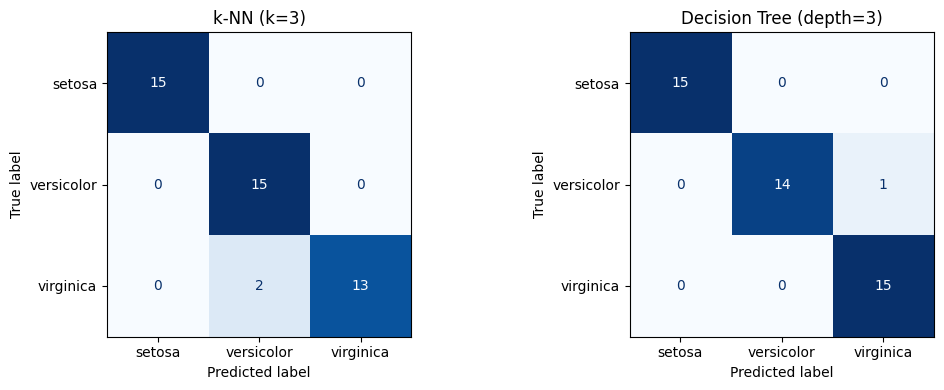


Model Comparison
Model                       Accuracy    Precision     Recall   F1-score
k-NN (k=3)                    0.9556       0.9608     0.9556     0.9554
Decision Tree (depth=3)       0.9778       0.9792     0.9778     0.9778

Preferred model for this split: Decision Tree (depth=3)


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    precision_recall_fscore_support, ConfusionMatrixDisplay
)

# Load Iris dataset
iris = load_iris()
X, y = iris.data, iris.target
names = iris.target_names

# Split: 70% training, 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

print("Iris samples:", X.shape)
print("Training:", len(y_train), "| Testing:", len(y_test))
print("Class order:", list(names))

# Define models
models = [
    ("k-NN (k=3)", KNeighborsClassifier(n_neighbors=3)),
    ("Decision Tree (depth=3)",
     DecisionTreeClassifier(max_depth=3, random_state=42))
]

results = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Train and evaluate
for (name, model), ax in zip(models, axes):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    acc = accuracy_score(y_test, pred)
    p, r, f1, _ = precision_recall_fscore_support(
        y_test, pred, average="macro", zero_division=0
    )
    results.append((name, acc, p, r, f1))

    print("\n", name)
    print("Accuracy:", round(acc, 4))
    print("Confusion Matrix:\n", confusion_matrix(y_test, pred))
    print("Macro Precision:", round(p, 4))
    print("Macro Recall:", round(r, 4))
    print("Macro F1-score:", round(f1, 4))
    print(classification_report(
        y_test, pred, target_names=names, zero_division=0
    ))

    wrong = np.where(pred != y_test)[0]
    print("Misclassified test rows:")
    for i in wrong:
        print(i, "| Actual:", names[y_test[i]],
              "| Predicted:", names[pred[i]])

    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=names,
        cmap="Blues", values_format="d",
        colorbar=False, ax=ax
    )
    ax.set_title(name)

# Display confusion matrices
plt.tight_layout()
plt.show()

# Compare models
print("\nModel Comparison")
print("{:<25} {:>10} {:>12} {:>10} {:>10}".format(
    "Model", "Accuracy", "Precision", "Recall", "F1-score"
))

for name, acc, p, r, f1 in results:
    print("{:<25} {:>10.4f} {:>12.4f} {:>10.4f} {:>10.4f}".format(
        name, acc, p, r, f1
    ))

# Select preferred model by accuracy, then F1-score
winner = max(results, key=lambda x: (x[1], x[4]))
print("\nPreferred model for this split:", winner[0])


### Result interpretation and discussion
The preferred algorithm is chosen using the **displayed metrics for this fixed split**, prioritizing accuracy and breaking ties by macro F1. Another split may reverse the ranking. The 45-case test set is relatively small, and neither method is automatically superior; real research would compare repeated cross-validation and independent holdout performance.

---
## Q4. Viva voce (10 marks)

| Question | Concise answer |
|:--|:--|
| What is an asserted fact? | A proposition initially placed into the KB. |
| What is an inferred fact? | A new proposition derived using rules. |
| Difference between BFS and A*? | BFS minimizes edge count; A* uses costs g+h. |
| Greedy drawback? | It may favor a low h while ignoring high path cost g. |
| Confusion matrix? | Counts of actual versus predicted classes. |
| Precision? | Share of predicted positives that are truly positive. |
| Recall? | Share of actual positives correctly predicted. |
| F1? | Harmonic mean of precision and recall. |

| What is forward chaining? | Start with known facts and repeatedly apply rules whose premises are satisfied. |
| Does a shortest path in edges always have the lowest cost? | No. When edges have different costs, a path with fewer edges can cost more. |
| What is the F1 score? | The harmonic mean of precision and recall: F1 = 2PR/(P+R), when P+R is positive. |

**Review tip:** Explain the code by identifying the inputs, data structures, stopping conditions, evaluation metrics, and one limitation for each task.

---
### Submission checklist
- [ ] Execute every Python cell in sequence; check the saved output is current.
- [ ] Explain the main formula, trace, and interpretation for Q1, Q2, Q3.
- [ ] Record the original task settings, dataset, random seed, and actual test metrics.
- [ ] For WEKA tasks, run WEKA locally and attach the real result-buffer output/screenshot; notebook instructions **do not substitute for WEKA evidence**.
- [ ] Be ready to discuss one methodological limitation in viva.

**Integrity note:** Code and explanations are independently written for this study repository. Numeric results are calculated from the shown code and may vary with library versions where numerical or tie-breaking differences occur.